In [19]:
import numpy as np
import pandas as pd

# Jatin's version 
## Ctrl+A and uncomment and comment next code block to run this

In [20]:
import numpy as np

class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

class Decision_Tree:
    def __init__(self, max_depth=10, min_samples_split=5):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

    
    # -------------------------
    # Entropy
    # -------------------------
    def entropy(self, y):
        counts = np.bincount(y.ravel())
        probs = counts[counts > 0] / len(y)
        return -np.sum(probs * np.log2(probs))

    # -------------------------
    # Information Gain
    # -------------------------
    def information_gain(self, X_column, y, threshold):
        parent_entropy = self.entropy(y)

        left_idx = X_column < threshold
        right_idx = ~left_idx

        if left_idx.sum() == 0 or right_idx.sum() == 0:
            return 0

        n = len(y)
        n_left = left_idx.sum()
        n_right = right_idx.sum()

        left_entropy = self.entropy(y[left_idx])
        right_entropy = self.entropy(y[right_idx])

        child_entropy = (n_left/n) * left_entropy + (n_right/n) * right_entropy

        return parent_entropy - child_entropy

    # -------------------------
    # Best Split
    # -------------------------
    def best_split(self, X, y, indices):
        best_gain = -1
        best_feature = None
        best_threshold = None

        X_sub = X[indices]
        y_sub = y[indices]

        n_features = X.shape[1]

        for feature in range(n_features):
            values = X_sub[:, feature]
            thresholds = np.unique(values)

            for threshold in thresholds:
                gain = self.information_gain(values, y_sub, threshold)
                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold, best_gain
    

    # -------------------------
    # Tree Builder
    # -------------------------
    def buildTree(self, X, y, indices, depth):
        y_sub = y[indices]

        if depth >= self.max_depth or len(indices) < self.min_samples_split or len(np.unique(y_sub)) == 1:
            return Node(value=self.majority_vote(y_sub))

        feature, threshold, gain = self.best_split(X, y, indices)

        if gain <= 0:
            return Node(value=self.majority_vote(y_sub))

        X_sub = X[indices]

        left_idx = indices[X_sub[:, feature] < threshold]
        right_idx = indices[X_sub[:, feature] >= threshold]

        left_child = self.buildTree(X, y, left_idx, depth+1)
        right_child = self.buildTree(X, y, right_idx, depth+1)

        return Node(feature=feature, threshold=threshold,
                    left=left_child, right=right_child)

    # -------------------------
    # Utility
    # -------------------------
    def majority_vote(self, y):
        values, counts = np.unique(y, return_counts=True)
        return values[np.argmax(counts)]

    # -------------------------
    # Fit
    # -------------------------
    def fit(self, X, y):
        indices = np.arange(len(X))
        self.root = self.buildTree(X, y, indices, 0)

    # -------------------------
    # Predict
    # -------------------------
    def predict_one(self, x, node):
        if node.value is not None:
            return node.value
        if x[node.feature] < node.threshold:
            return self.predict_one(x, node.left)
        else:
            return self.predict_one(x, node.right)

    def predict(self, X):
        return np.array([self.predict_one(x, self.root) for x in X])

In [21]:
df = pd.read_csv("../data/lifestyle_disease_transformed.csv")
df = df.drop(["Unnamed: 0"], axis=1)
print(df.info())
target = df.iloc[:,-1:]
features = df.iloc[:,:-1]

x_train = features[:300000]
y_train = target[:300000]
x_test = features[300000:]
y_test = target[300000:]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 12 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Age            500000 non-null  int64  
 1   Gender         500000 non-null  int64  
 2   BMI            500000 non-null  float64
 3   Smoking        500000 non-null  int64  
 4   Alcohol        500000 non-null  int64  
 5   ExerciseHours  500000 non-null  float64
 6   SleepHours     500000 non-null  float64
 7   DietScore      500000 non-null  int64  
 8   BloodPressure  500000 non-null  int64  
 9   BloodSugar     500000 non-null  int64  
 10  Cholesterol    500000 non-null  int64  
 11  DiseaseRisk    500000 non-null  int64  
dtypes: float64(3), int64(9)
memory usage: 45.8 MB
None


In [22]:
model = Decision_Tree(max_depth=10)
model.fit(x_train.values, y_train.values)

In [23]:
y_pred = model.predict(x_test.values)

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,auc,roc_auc_score,roc_curve
def statistical_outcomes(x,y):
    mat = confusion_matrix(x,y)
    acc = accuracy_score(x,y)
    pre = precision_score(x,y)
    rec = recall_score(x,y)
    f1s = f1_score(x,y)
    _roc = roc_auc_score(x,y)
    print("Confusion matrix: \n",mat)
    print("Accuracy Score: \n",acc)
    print("Precision Score: \n",pre)
    print("Recall Score: \n",rec)
    print("F1 Score: \n",f1s)
    print("ROC_AUC Score: \n",_roc)
    p,q,r = roc_curve(y_test,y_pred)
    plt.plot(p,q)
    plt.xlabel("fpr")
    plt.ylabel("tpr")
    plt.title("Roc_curve")
    plt.show()


Confusion matrix: 
 [[140318      0]
 [     0  59682]]
Accuracy Score: 
 1.0
Precision Score: 
 1.0
Recall Score: 
 1.0
F1 Score: 
 1.0
ROC_AUC Score: 
 1.0


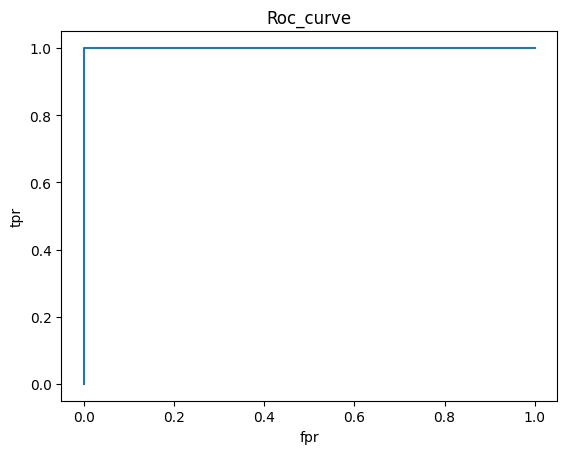

In [25]:
statistical_outcomes(y_test,y_pred)